# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
def trapezoidal(func, n, a, b):
    h = (b - a) / n  
    s = (func(a) + func(b)) / 2.0
    for k in range(1, n):
        s += func(a + k * h)  
    return h * s

def simpson13(func, n, a, b):
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    cs = np.ones(n + 1)
    cs[1:-1:2] = 4  # Odd indices
    cs[2:-2:2] = 2  # Even indices 
    return (h / 3) * np.sum(cs * func(xs))

def simpson38(func, n, a, b):
    h = (b - a) / n
    xs = np.linspace(a, b, n + 1)
    cs = np.ones(n + 1) * 3
    cs[0] = 1
    cs[-1] = 1
    cs[3:-3:3] = 2  
    return (3 * h / 8) * np.sum(cs * func(xs))

def montecarlo(func, n, a, b):
    xs = np.linspace(a, b, 1000)
    ys = func(xs)
    
    # Establish bounding box 
    ymin = min(0, np.min(ys))
    ymax = max(0, np.max(ys))
    
    x_rand = np.random.uniform(a, b, n)
    y_rand = np.random.uniform(ymin, ymax, n)
    
    blue_pts = (y_rand > 0) & (y_rand <= func(x_rand))
    red_pts = (y_rand < 0) & (y_rand >= func(x_rand))
    
    box_area = (b - a) * (ymax - ymin)
    
    signed_area = box_area * (np.sum(blue_pts) - np.sum(red_pts)) / n
    total_area = box_area * (np.sum(blue_pts) + np.sum(red_pts)) / n
    
    return signed_area, total_area, x_rand, y_rand, blue_pts, red_pts

In [3]:
# Initialize the bounds and N
a_bounds = [0, -2, 0]
b_bounds = [3/2, 2, np.pi]
N = 1200 

# Define the functions to be integrated
functions = [
    lambda x: np.sqrt(9 - 4 * x ** 2),
    lambda x: (-x**2 + 1),
    lambda x: (np.sqrt(x) * np.cos(x)),
]

func_names = [
    r"$y = \sqrt{9 - 4x^2}$",
    r"$y = -x^2 + 1$",
    r"$y = \sqrt{x}\cos(x)$"]

# N values must be multiples of 6 (even for Simpson 1/3, multiple of 3 for Simpson 3/8)
N_values = [6, 12, 60, 120, 300, 600, 1200]

In [4]:
for i, (func, a, b) in enumerate(zip(functions, a_bounds, b_bounds)):
    print(f"\n Function {i+1} : Bounds [{a}, {b:.4f}]")
    
    scipy_integral, _ = quad(func, a, b)
    
    # Newton-Cotes Integrals (Signed Area)
    trap_int = trapezoidal(func, N, a, b)
    simp13_int = simpson13(func, N, a, b)
    simp38_int = simpson38(func, N, a, b)
    
    # Newton-Cotes Total Area (Absolute value of the function)
    abs_func = lambda x: np.abs(func(x))
    trap_tot = trapezoidal(abs_func, N, a, b)
    
    # Monte Carlo (returns both area types and plotting data)
    mc_int, mc_tot, x_rand, y_rand, blue_pts, red_pts = montecarlo(func, 10000, a, b)

    print(f"Scipy Integral      : {scipy_integral:.6f}")
    print(f"Trapezoidal Integral: {trap_int:.6f} | Total Area: {trap_tot:.6f}")
    print(f"Simpson 1/3 Integral: {simp13_int:.6f}")
    print(f"Simpson 3/8 Integral: {simp38_int:.6f}")
    print(f"Monte Carlo Integral: {mc_int:.6f} | Total Area: {mc_tot:.6f}")


 Function 1 : Bounds [0, 1.5000]
Scipy Integral      : 3.534292
Trapezoidal Integral: 3.534260 | Total Area: 3.534260
Simpson 1/3 Integral: 3.534279
Simpson 3/8 Integral: 3.534277
Monte Carlo Integral: 3.546450 | Total Area: 3.546450

 Function 2 : Bounds [-2, 2.0000]
Scipy Integral      : -1.333333
Trapezoidal Integral: -1.333341 | Total Area: 4.000000
Simpson 1/3 Integral: -1.333333
Simpson 3/8 Integral: -1.333333
Monte Carlo Integral: -1.246399 | Total Area: 4.087996

 Function 3 : Bounds [0, 3.1416]
Scipy Integral      : -0.894831
Trapezoidal Integral: -0.894859 | Total Area: 2.302878
Simpson 1/3 Integral: -0.894842
Simpson 3/8 Integral: -0.894845
Monte Carlo Integral: -0.869207 | Total Area: 2.313334


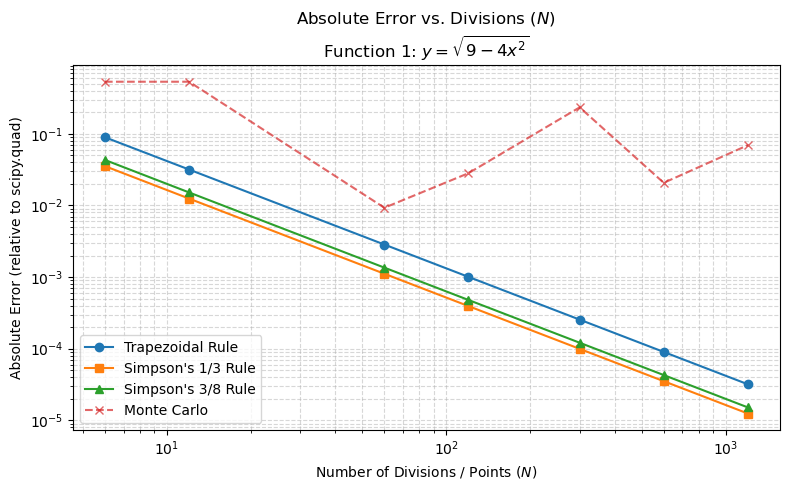

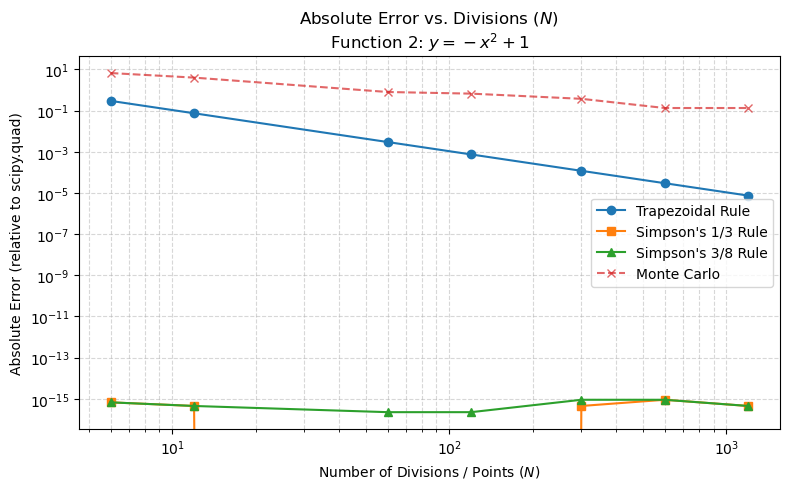

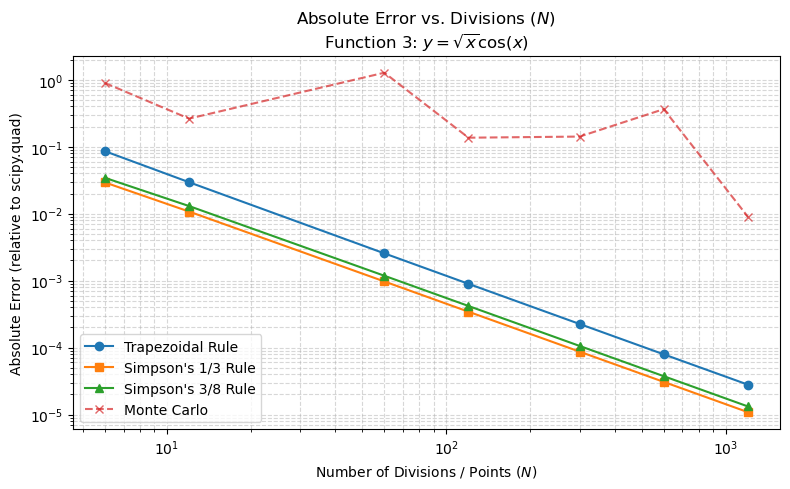

In [5]:
func_names = [
    r"$y = \sqrt{9 - 4x^2}$",
    r"$y = -x^2 + 1$",
    r"$y = \sqrt{x}\cos(x)$"]

# N values must be multiples of 6 (even for Simpson 1/3, multiple of 3 for Simpson 3/8)
N_values = [6, 12, 60, 120, 300, 600, 1200]

# Plot the figures
for i, (func, a, b, name) in enumerate(zip(functions, a_bounds, b_bounds, func_names)):
    scipy_integral, _ = quad(func, a, b)
    
    # Lists to store the errors
    trap_errors = []
    simp13_errors = []
    simp38_errors = []
    mc_errors = []
    
    for n in N_values:
        trap_errors.append(abs(trapezoidal(func, n, a, b) - scipy_integral))
        simp13_errors.append(abs(simpson13(func, n, a, b) - scipy_integral))
        simp38_errors.append(abs(simpson38(func, n, a, b) - scipy_integral))
        
        # Monte Carlo error (average over a run for stability)
        mc_int, _, _, _, _, _ = montecarlo(func, n, a, b)
        mc_errors.append(abs(mc_int - scipy_integral))

    # Absolute Error vs N 
    plt.figure(figsize=(8, 5))
    plt.loglog(N_values, trap_errors, 'o-', label='Trapezoidal Rule')
    plt.loglog(N_values, simp13_errors, 's-', label="Simpson's 1/3 Rule")
    plt.loglog(N_values, simp38_errors, '^-', label="Simpson's 3/8 Rule")
    plt.loglog(N_values, mc_errors, 'x--', label='Monte Carlo', alpha=0.7)
    
    plt.title(f"Absolute Error vs. Divisions ($N$)\nFunction {i+1}: {name}")
    plt.xlabel("Number of Divisions / Points ($N$)")
    plt.ylabel("Absolute Error (relative to scipy.quad)")
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

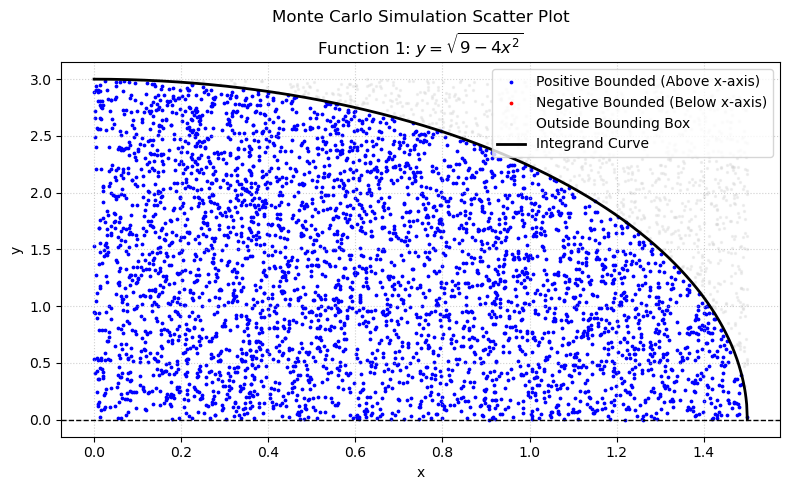

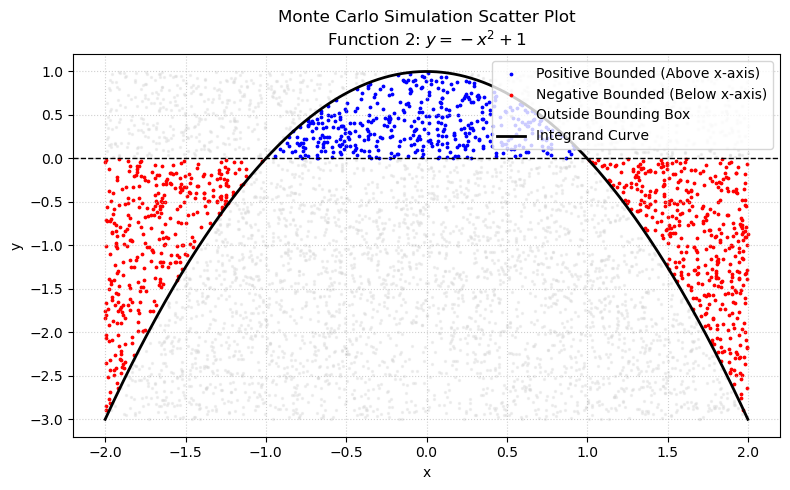

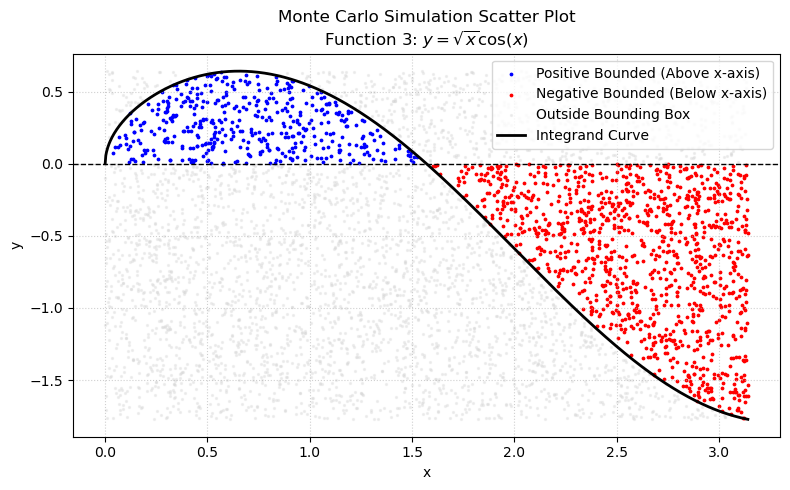

In [6]:
# Monte Carlo Bounded Points Scatter Plot
for i, (func, a, b, name) in enumerate(zip(functions, a_bounds, b_bounds, func_names)):
    mc_int, mc_tot, x_rand, y_rand, blue_pts, red_pts = montecarlo(func, 5000, a, b)
    
    plt.figure(figsize=(8, 5))
    
    # Plot bounded points (Blue = above x-axis, Red = below x-axis)
    plt.scatter(x_rand[blue_pts], y_rand[blue_pts], color='blue', s=3, label='Positive Bounded (Above x-axis)')
    plt.scatter(x_rand[red_pts], y_rand[red_pts], color='red', s=3, label='Negative Bounded (Below x-axis)')
    
    # Plot points outside the bounded region in light gray to display the bounding box
    outside_pts = ~blue_pts & ~red_pts
    plt.scatter(x_rand[outside_pts], y_rand[outside_pts], color='lightgray', s=2, alpha=0.3, label='Outside Bounding Box')
    
    # Overlay actual curve and x-axis baseline
    xs = np.linspace(a, b, 1000)
    plt.plot(xs, func(xs), color='black', linewidth=2, label='Integrand Curve')
    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    
    plt.title(f"Monte Carlo Simulation Scatter Plot\nFunction {i+1}: {name}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend(loc='upper right')
    plt.grid(True, ls=":", alpha=0.6)
    plt.tight_layout()
    plt.show()